# Installation

In [1]:
import os, shutil, subprocess

# Ohne GPU benötigt Dr.Jit das LLVM-Backend (libLLVM)
HAS_GPU = shutil.which("nvidia-smi") is not None and subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
if not HAS_GPU and os.getenv("COLAB_RELEASE_TAG"):
    subprocess.run("apt-get -qq update && apt-get -qq install -y llvm > /dev/null", shell=True)

try:
    import sionna.rt
except ImportError:
    subprocess.run("pip install -q sionna-rt==2.2.0 h5py", shell=True, check=True)
    import sionna.rt

print("GPU:", HAS_GPU, "| Sionna RT", sionna.rt.__version__)

GPU: True | Sionna RT 2.2.0


In [2]:
import time
from pathlib import Path
from typing import Literal
from dataclasses import asdict, dataclass
from scipy.ndimage import binary_erosion, label
from scipy.spatial import cKDTree

import h5py
import matplotlib.pyplot as plt
import drjit as dr
import mitsuba as mi
import numpy as np
import sionna.rt as rt

from sionna.rt import PathSolver, PlanarArray, Receiver, Transmitter, load_scene, Camera

## Konfuguration

In [22]:
CFG = {
    "scene": "etoile", #  Predefined scenes available: ["munich", "etoile", "florence", "san_francisco"]
    "frequency_hz": 1.57542e9, #  Jammer signal frequency
    "tx_power_dbm": 35.0, #  Jammer power strength

    "n_sensors": 25, #  Amount of Sensors placed in the scene
    "sensor_height_m": 1.5, #  Height above ground
    "jammer_height_m": 3.0, #  Height above ground

    "episodes": 100, #  Amount of episodes to run (one episode = one jamming scneario)
    "n_steps": 10, #  Time Steps within an episode
    "dt_s": 1.0, #  Time within the time steps
    "speed_mps": 3.0, #  Speed of the random walk -- TODO: Which random walk is suiting best - Should only walk on streets - GBM?

    "batch": 4, #  Batch Size
    "max_depth": 3, #  Sionna: Depth of Raytracing bounding
    "samples_per_src": 100_000, # Sionna: Amount of raytracing samples, leaving a jammer
    "seed": 42,
    "out_dir": Path("outputs/sionna_dynamic"),
}

CFG["out_dir"].mkdir(parents=True, exist_ok=True)

print("Sionna RT:", rt.__version__)
print("Mitsuba backend:", mi.variant())

Sionna RT: 2.2.0
Mitsuba backend: cuda_ad_mono_polarized


## Code

In [33]:
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Literal

import h5py
import mitsuba as mi
import numpy as np
import sionna.rt as rt
from scipy.ndimage import binary_erosion, label
from scipy.spatial import cKDTree
from sionna.rt import PathSolver, PlanarArray, Receiver, Transmitter, load_scene


@dataclass(frozen=True)
class DataConfig:
    scene_name: Literal["munich", "etoile", "florence", "san_francisco"] = "etoile"
    frequency_hz: float = 3.5e9
    tx_power_dbm: float = 20.0
    sensitivity_dbm: float = -110.0
    rssi_noise_std_db: float = 0.0
    max_depth: int = 3
    samples_per_src: int = 20_000
    batch_size: int = 8

    roi_center_xy_m: tuple[float, float] = (0.0, 0.0)
    roi_half_size_m: float = 150.0
    grid_resolution_m: float = 3.0
    ground_tolerance_m: float = 0.5
    erosion_iterations: int = 1
    n_sensors: int = 20
    sensor_height_m: float = 1.5
    jammer_height_m: float = 1.5
    sensor_placement: Literal["random", "spread"] = "spread"
    graph_neighbors: int = 3 # kNN

    episodes: int = 32
    n_steps: int = 60
    dt_s: float = 1.0
    speed_mps: float = 1.5
    heading_std_rad: float = 0.25
    seed: int = 42
    test_fraction: float = 0.2
    output_dir: Path = Path("datasets")
    overwrite: bool = False
    debug: bool = False
    chunk_episodes: int = 64
    auto_center_roi: bool = True


@dataclass
class WalkableMap:
    x_m: np.ndarray
    y_m: np.ndarray
    height_m: np.ndarray   # [Y, X]: ground / roof surface height
    free: np.ndarray       # [Y, X]: approximate usable ground cells
    resolution_m: float

    def lookup(self, xy: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """Return (is_free, surface_height) for arbitrary XY positions."""
        xy = np.atleast_2d(xy)
        ix = np.floor((xy[:, 0] - self.x_m[0]) / self.resolution_m + 0.5).astype(int)
        iy = np.floor((xy[:, 1] - self.y_m[0]) / self.resolution_m + 0.5).astype(int)
        inside = (ix >= 0) & (ix < self.free.shape[1]) & (iy >= 0) & (iy < self.free.shape[0])
        usable = np.zeros(len(xy), dtype=bool)
        heights = np.full(len(xy), np.nan, dtype=np.float32)
        usable[inside] = self.free[iy[inside], ix[inside]]
        heights[inside] = self.height_m[iy[inside], ix[inside]]
        return usable, heights

    def candidates(self) -> np.ndarray:
        """Centers of free map cells, with shape [N, 2]."""
        iy, ix = np.nonzero(self.free)
        return np.column_stack((self.x_m[ix], self.y_m[iy]))

In [34]:
def load_environment(cfg: DataConfig) -> tuple[rt.Scene, WalkableMap]:
    scene = load_scene(getattr(rt.scene, cfg.scene_name), merge_shapes=True) # Merge shapes for faster computation
    scene.frequency = cfg.frequency_hz
    antenna = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
    scene.tx_array = scene.rx_array = antenna

    bbox = scene.mi_scene.bbox()
    if cfg.auto_center_roi:
        roi_center_xy = (
            (float(bbox.min.x) + float(bbox.max.x)) / 2,
            (float(bbox.min.y) + float(bbox.max.y)) / 2,
        )
    else:
        roi_center_xy = cfg.roi_center_xy_m

    n = int(np.floor(2 * cfg.roi_half_size_m / cfg.grid_resolution_m))
    if n < 2:
        raise ValueError("ROI is too small for the grid resolution")
    centers = -cfg.roi_half_size_m + (np.arange(n) + 0.5) * cfg.grid_resolution_m
    #x_m, y_m = (centers + shift for shift in cfg.roi_center_xy_m)
    x_m, y_m = (
        centers + roi_center_xy[0],
        centers + roi_center_xy[1],
    )
    xx, yy = np.meshgrid(x_m, y_m)


    z_top = float(bbox.max.z) + 10.0
    origins = mi.Point3f(xx.ravel().astype('float32'), yy.ravel().astype('float32'), np.full(xx.size, z_top, dtype='float32'))
    hits = scene.mi_scene.ray_intersect(mi.Ray3f(origins, mi.Vector3f(0, 0, -1)))
    valid = np.asarray(hits.is_valid().numpy()).reshape(xx.shape)
    height = np.where(valid, z_top - np.asarray(hits.t.numpy()).reshape(xx.shape), np.nan)

    # Flat-ground approximation: reject roofs, then remove edge cells and isolated islands.
    ground = valid & (np.abs(height - float(bbox.min.z)) <= cfg.ground_tolerance_m)
    if cfg.erosion_iterations:
        ground = binary_erosion(ground, iterations=cfg.erosion_iterations)
    components, count = label(ground)
    if count == 0:
        raise ValueError("No walkable ground found; adjust ROI / ground tolerance")
    sizes = np.bincount(components.ravel())
    sizes[0] = 0

    return scene, WalkableMap(x_m, y_m, height, components == sizes.argmax(), cfg.grid_resolution_m)

cfg = DataConfig(debug = True)
scene, grid = load_environment(cfg)

In [35]:
def setup_sensors(scene: rt.Scene, grid: WalkableMap, cfg: DataConfig, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
    candidates = grid.candidates()
    if cfg.n_sensors > len(candidates) or cfg.n_sensors < 1:
        raise ValueError("n_sensors must be between 1 and the number of free cells")

    if cfg.sensor_placement == "random":
        chosen = rng.choice(len(candidates), cfg.n_sensors, replace=False)
    else:
        # Farthest-point sampling spreads sensors across the scene.
        chosen = [int(rng.integers(len(candidates)))]
        distances = np.sum((candidates - candidates[chosen[0]])**2, axis=1)
        for _ in range(cfg.n_sensors - 1):
            distances[chosen] = -1
            chosen.append(int(np.argmax(distances)))
            distances = np.minimum(distances, np.sum((candidates - candidates[chosen[-1]])**2, axis=1))

    xy = candidates[chosen]
    _, ground_z = grid.lookup(xy)
    positions = np.column_stack((xy, ground_z + cfg.sensor_height_m)).astype('float32')
    for i, pos in enumerate(positions):
        scene.add(Receiver(name=f"sensor_{i:03d}", position=pos.tolist()))

    # Create Graph using KNN
    k = min(max(0, cfg.graph_neighbors), cfg.n_sensors - 1)
    edges = np.empty((2, 0), dtype=np.int64)
    if k:
        _, nearest = cKDTree(positions[:, :2]).query(positions[:, :2], k=k + 1)
        src = np.repeat(np.arange(len(positions)), k)
        dst = nearest[:, 1:].ravel()
        pairs = np.column_stack((np.r_[src, dst], np.r_[dst, src]))
        edges = np.unique(pairs, axis=0).T.astype(np.int64)

    return positions, edges

sensors, edges = setup_sensors(scene, grid, cfg, np.random.default_rng(42))

In [36]:
def generate_trajectories(grid: WalkableMap, cfg: DataConfig, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
    positions = np.empty((cfg.episodes, cfg.n_steps, 3), dtype=np.float32)
    candidates = grid.candidates()
    step = cfg.speed_mps * cfg.dt_s
    checks = max(3, int(np.ceil(step / (cfg.grid_resolution_m / 2))) + 1)

    for e in range(cfg.episodes):
        xy = candidates[rng.integers(len(candidates))].copy()
        heading = rng.uniform(0, 2 * np.pi)
        for t in range(cfg.n_steps):
            _, ground_z = grid.lookup(xy)
            positions[e, t] = (*xy, ground_z[0] + cfg.jammer_height_m)
            if t == cfg.n_steps - 1 or step == 0:
                continue
            for attempt in range(32):
                direction = (heading + rng.normal(0, cfg.heading_std_rad)
                             if attempt == 0 else rng.uniform(0, 2 * np.pi))
                move = step * np.array([np.cos(direction), np.sin(direction)])
                samples = xy + np.linspace(0, 1, checks)[:, None] * move
                if grid.lookup(samples)[0].all():
                    xy, heading = xy + move, direction
                    break

    velocity = np.zeros_like(positions)
    velocity[:, 1:] = np.diff(positions, axis=1) / cfg.dt_s
    return positions, velocity

positions, velocities = generate_trajectories(grid, cfg, np.random.default_rng(42))

In [37]:

from time import perf_counter
from tqdm.auto import tqdm


def simulate_links(scene: rt.Scene, positions: np.ndarray, cfg: DataConfig) -> dict:
    e, t, _ = positions.shape
    points = positions.reshape(-1, 3)
    q = len(points)
    n_rx = len(scene.receivers)

    if q == 0 or n_rx == 0: raise ValueError("Missing jammer positions and receivers")
    if cfg.batch_size < 1: raise ValueError("batch_size must be positive")

    B = min(cfg.batch_size, q)

    arrays = {
        "path_gain_linear": np.empty((q, n_rx), dtype=np.float32),
        "los": np.empty((q, n_rx), dtype=bool),
        "num_paths": np.empty((q, n_rx), dtype=np.int32),
    }

    scene.remove(list(scene.transmitters))

    # Create reusable transmitter slots. Otherwise we recompute plenty of times within the loop
    tx_slots = [
        Transmitter(
            name=f"jammer_slot_{i:03d}",
            position=points[0].tolist(),
            power_dbm=cfg.tx_power_dbm,
        )
        for i in range(B)
    ]

    scene.add(tx_slots)

    solver = PathSolver(deterministic=True)

    def link_axes(values):
        values = np.asarray(values)
        return values[:, 0, :, 0, :] if values.ndim == 5 else values

    start_time = perf_counter()

    try:
        for start in tqdm(range(0, q, B), desc="Ray tracing"):
            batch = points[start:start + B]
            n = len(batch)

            for i, slot in enumerate(tx_slots):
                p = batch[min(i, n - 1)]
                slot.position = mi.Point3f(*map(float, p))

            paths = solver(
                scene,
                max_depth=cfg.max_depth,
                samples_per_src=cfg.samples_per_src,
                synthetic_array=True,
                los=True,
                specular_reflection=True,
                diffuse_reflection=False,
                refraction=False,
                diffraction=False,
                seed=cfg.seed + start,
            )

            # Converting Sionna path tensors to NumPy.
            re, im = (
                link_axes(component.numpy())
                for component in paths.a
            )

            valid = link_axes(np.asarray(paths.valid.numpy(), dtype=bool))
            direct = link_axes((np.asarray(paths.interactions.numpy()) == 0).all(axis=0))

            if not (re.shape == im.shape == valid.shape == direct.shape):
                raise RuntimeError(f"Incompatible path tensor shapes: {re.shape}, {im.shape}, {valid.shape}, {direct.shape}")

            statistics = {
                "path_gain_linear": np.where(valid, re**2 + im**2, 0).sum(axis=-1),
                "los": (valid & direct).any(axis=-1),
                "num_paths": valid.sum(axis=-1),
            }

            for key, values in statistics.items():
                if values.shape != (n_rx, B):
                    raise RuntimeError(f"Unexpected {key} shape: {values.shape}")
                arrays[key][start:start + n] = values.T[:n]

    finally:
        # Clean up only our transmitter slots.
        scene.remove([slot.name for slot in tx_slots])

    elapsed = perf_counter() - start_time

    print(f"Solver time: {elapsed:.2f} s")
    print(f"Time per position: {1000 * elapsed / q:.2f} ms")

    return {
        key: values.reshape(e, t, n_rx)
        for key, values in arrays.items()
    }

def add_measurements(links: dict, cfg: DataConfig, rng: np.random.Generator) -> dict:
    gain = links["path_gain_linear"]
    gain_db = np.full(gain.shape, np.nan, dtype=np.float32)
    np.log10(gain, where=gain > 0, out=gain_db)
    gain_db *= 10
    rssi = cfg.tx_power_dbm + gain_db
    if cfg.rssi_noise_std_db > 0:
        rssi += rng.normal(0, cfg.rssi_noise_std_db, size=gain.shape)
    detected = np.isfinite(rssi) & (rssi >= cfg.sensitivity_dbm)
    return {**links, "path_gain_db": gain_db, "rssi_dbm": np.where(detected, rssi, np.nan).astype(np.float32), "detected": detected}

measurements = add_measurements(simulate_links(scene, positions, cfg), cfg, np.random.default_rng(42))

Ray tracing:   0%|          | 0/240 [00:00<?, ?it/s]

Solver time: 35.06 s
Time per position: 18.26 ms


In [38]:
def save_dataset(cfg: DataConfig, grid: WalkableMap, sensors: np.ndarray, edges: np.ndarray, positions: np.ndarray, velocities: np.ndarray, measurements: dict, rng: np.random.Generator) -> Path:
    cfg.output_dir.mkdir(parents=True, exist_ok=True)
    output = cfg.output_dir / f"{cfg.scene_name}_seed{cfg.seed}.h5"
    if output.exists() and not cfg.overwrite:
        raise FileExistsError(f"{output} already exists")

    perm = rng.permutation(cfg.episodes)
    n_test = (min(cfg.episodes - 1, max(1, round(cfg.episodes * cfg.test_fraction))) if cfg.episodes > 1 and cfg.test_fraction > 0 else 0)
    datasets = {
        "sensors/positions": sensors,
        "graph/edge_index": edges,
        "jammer/positions": positions,
        "jammer/velocities": velocities,
        "jammer/time_s": np.arange(cfg.n_steps, dtype=np.float32) * cfg.dt_s,
        **{f"measurements/{name}": values for name, values in measurements.items()},
        "map/free": grid.free,
        "map/surface_height_m": grid.height_m,
        "map/x_m": grid.x_m,
        "map/y_m": grid.y_m,
        "split/train_episodes": np.sort(perm[n_test:]),
        "split/test_episodes": np.sort(perm[:n_test]),
    }
    with h5py.File(output, 'w') as file:
        for name, value in asdict(cfg).items():
            file.attrs[name] = str(value) if isinstance(value, Path) else value
        file.attrs.update(axis_order="episode,time_step,sensor", rssi_model="incoherent_path_power_sum", mitsuba_variant=mi.variant(), sionna_rt_version=getattr(rt, "__version__", "unknown"))
        for name, values in datasets.items():
            file.create_dataset(name, data=values, compression='gzip', compression_opts=4, shuffle=True)
    return output

In [39]:
def generate_data_for_scene(cfg: DataConfig) -> Path:
    output = cfg.output_dir / f"{cfg.scene_name}_seed{cfg.seed}.h5"
    if output.exists() and not cfg.overwrite:
        raise FileExistsError(f"{output} already exists")
    if cfg.dt_s <= 0 or cfg.n_steps < 1 or cfg.episodes < 1 or cfg.batch_size < 1:
        raise ValueError("dt_s, n_steps, episodes and batch_size must be positive")

    scene, grid = load_environment(cfg)
    sensors, edges = setup_sensors(scene, grid, cfg, rng)
    positions, velocities = generate_trajectories(grid, cfg, rng)
    measurements = add_measurements(simulate_links(scene, positions, cfg), cfg, rng)
    output = save_dataset(cfg, grid, sensors, edges, positions, velocities, measurements, rng)
    print(f"Saved: {output} | Detection rate: {measurements['detected'].mean():.1%}")
    return output


## Vis

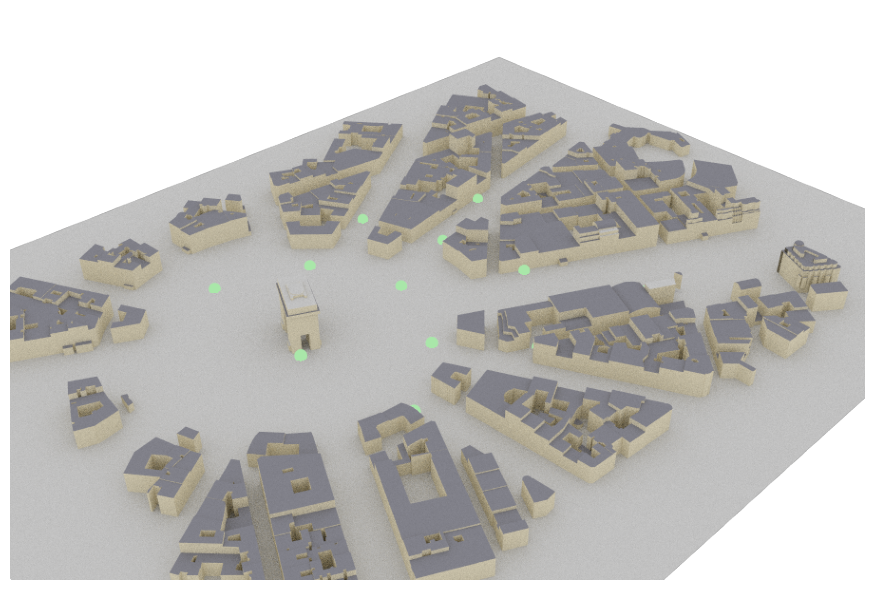

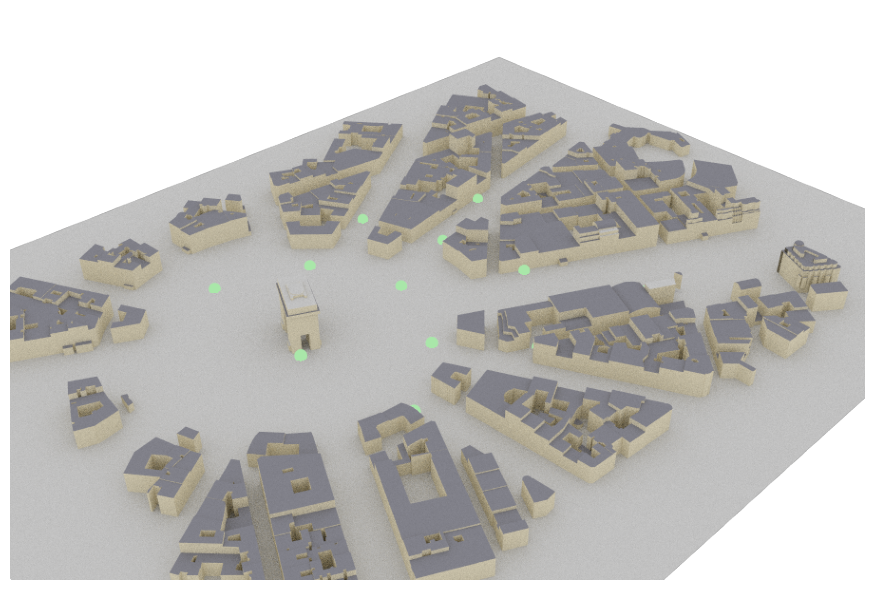

In [30]:
cam = Camera(position=[-520, -560, 560], look_at=[0, 0, 0])
scene.render(camera=cam, resolution=(900, 600), num_samples=64 if HAS_GPU else 16)

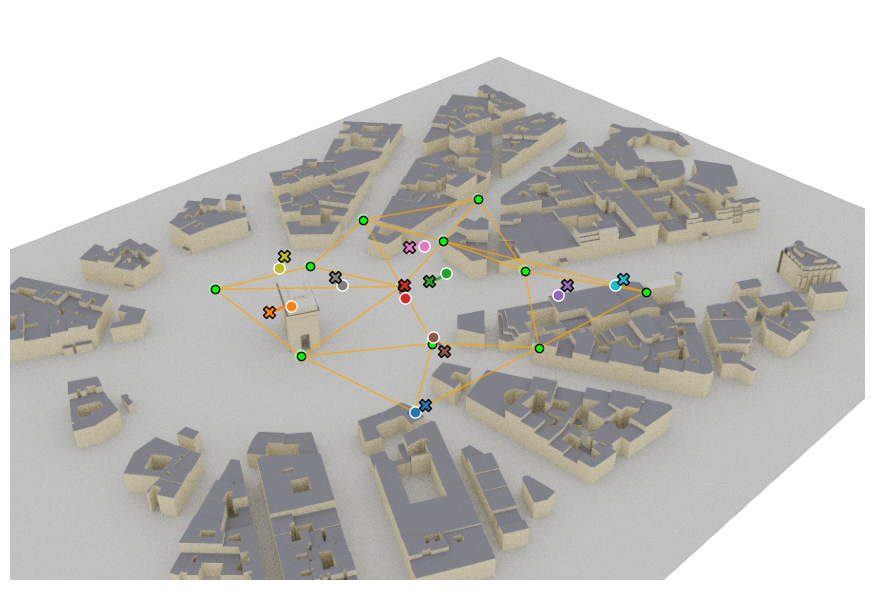

In [17]:
def debug_render(scene: rt.Scene, sensors: np.ndarray, edges: np.ndarray, trajectories: np.ndarray, max_episodes: int = 10, show_trajectories: bool = False):
    width, height = 900, 600
    fov = 45.0

    camera_pos = np.array([-520., -560., 560.])
    camera_target = np.array([0., 0., 0.])

    cam = Camera(position=camera_pos.tolist(), look_at=camera_target.tolist())

    # Render Sionna environment and receivers
    fig = scene.render(camera=cam,resolution=(width, height), num_samples=64 if HAS_GPU else 16, fov=fov, show_devices=True)
    ax = fig.axes[0]

    # Camera basis
    forward = camera_target - camera_pos
    forward /= np.linalg.norm(forward)

    right = np.cross(forward, [0., 0., 1.])
    right /= np.linalg.norm(right)
    up = np.cross(right, forward)

    focal = width / (2 * np.tan(np.deg2rad(fov) / 2))

    def project(points):
        """Project 3D points onto the rendered image."""
        relative = points - camera_pos
        depth = relative @ forward
        visible = depth > 1e-6

        u = np.full(len(points), np.nan)
        v = np.full(len(points), np.nan)

        u[visible] = width / 2 + focal * (relative[visible] @ right) / depth[visible]
        v[visible] = height / 2 - focal * (relative[visible] @ up) / depth[visible]
        return u, v

    # Sensor positions and graph edges
    sx, sy = project(sensors)

    for i, j in np.unique(np.sort(edges.T, axis=1), axis=0):
        ax.plot([sx[i], sx[j]], [sy[i], sy[j]], color="orange", linewidth=1.2, alpha=0.65, zorder=10)

    ax.scatter(sx, sy, c="lime", s=35, edgecolors="black", zorder=12)

    # Jammer trajectories: [episodes, steps, 3]
    colors = plt.get_cmap("tab10")

    if show_trajectories:
        for e, path in enumerate(trajectories[:max_episodes]):
            x, y = project(path)
            color = colors(e % 10)

            ax.plot(x, y, color=color, linewidth=2, alpha=0.9, zorder=13)

            # Starting position
            ax.scatter(x[0], y[0], color=color, marker="o", s=65, edgecolors="white", zorder=14)

            # Final position
            ax.scatter(x[-1], y[-1], color=color, marker="X", s=75, edgecolors="black", zorder=14,)

    ax.set_xlim(-0.5, width - 0.5)
    ax.set_ylim(height - 0.5, -0.5)
    ax.set_axis_off()

    plt.show()

if cfg.debug:
    debug_render(scene, sensors, edges, positions, max_episodes=10)

## Final Script for Data Generation

In [16]:
config = DataConfig(
    scene_name="etoile",
    episodes=32,
    n_steps=30,
    n_sensors=12,
    seed=42,
    output_dir=Path("datasets"),
)
generate_data_for_scene(config)


Ray tracing:   0%|          | 0/120 [00:00<?, ?it/s]

Solver time: 21.34 s
Time per position: 22.23 ms
Saved: datasets/etoile_seed42.h5 | Detection rate: 83.9%


PosixPath('datasets/etoile_seed42.h5')

In [ ]:

def generate_multi_scene_dataset(cfg, scene_names):

    if cfg.episodes < 1 or cfg.chunk_episodes < 1:
        raise ValueError("Episode counts must be positive")

    cfg.output_dir.mkdir(parents=True, exist_ok=True)

    for scene_index, scene_name in enumerate(scene_names):

        print(f"\n{'=' * 60}")
        print(f"Processing scene: {scene_name}")
        print(f"{'=' * 60}")

        scene_cfg = replace(
            cfg,
            scene_name=scene_name,
            debug=False,
        )

        output_path = cfg.output_dir / f"{scene_name}.h5"

        if cfg.overwrite and output_path.exists():
            output_path.unlink()

        # Load geometry once per scene
        scene, grid = load_environment(scene_cfg)

        # Fixed sensor layout throughout this scene
        sensor_rng = np.random.default_rng(
            np.random.SeedSequence([cfg.seed, scene_index, 101])
        )

        sensors, edges = setup_sensors(
            scene, grid, scene_cfg, sensor_rng
        )

        print(f"Sensors: {len(sensors)}")
        print(f"Walkable cells: {int(grid.free.sum())}")
        print(f"Graph edges: {edges.shape[1]}")

        with h5py.File(output_path, "a") as h5:

            completed = prepare_h5(
                h5, grid, sensors, edges, scene_cfg, scene_index
            )

            print(f"Resuming from episode {completed}")

            starts = range(
                completed,
                cfg.episodes,
                cfg.chunk_episodes
            )

            for start in tqdm(starts, desc=scene_name, unit="chunk"):

                n = min(
                    cfg.chunk_episodes,
                    cfg.episodes - start
                )

                # Different deterministic random streams per chunk
                trajectory_rng = np.random.default_rng(
                    np.random.SeedSequence(
                        [cfg.seed, scene_index, start, 1]
                    )
                )

                measurement_rng = np.random.default_rng(
                    np.random.SeedSequence(
                        [cfg.seed, scene_index, start, 2]
                    )
                )

                chunk_cfg = replace(
                    scene_cfg,
                    episodes=n,
                    seed=cfg.seed + scene_index * 1_000_000 + start,
                )

                # 1. Generate this chunk's jammer trajectories
                positions, velocities = generate_trajectories(
                    grid, chunk_cfg, trajectory_rng
                )

                # 2. Ray-trace links to fixed sensors
                links = simulate_links(
                    scene, positions, chunk_cfg
                )

                # 3. Calculate RSSI and detection
                measurements = add_measurements(
                    links, chunk_cfg, measurement_rng
                )

                # 4. Save and checkpoint
                append_episode_chunk(
                    h5,
                    start,
                    {
                        "positions": positions,
                        "velocities": velocities,
                        **measurements,
                    }
                )

                # Do not retain completed chunks in RAM
                del positions, velocities, links, measurements

        print(f"Finished: {output_path}")

        # Release this scene before loading the next one
        del scene, grid, sensors, edges

    print("\nAll requested scenes completed.")

SCENES = [
    "etoile",
    "munich",
    "florence",
    "san_francisco",
]
generate_multi_scene_dataset(cfg, SCENES)